# 03 | Zufall braucht Modellregeln

**Lernziele:** Einen Seed erklären, Gewichte in Wahrscheinlichkeiten
übersetzen und Ziehen mit bzw. ohne Zurücklegen unterscheiden.
**Vorwissen:** Listen, Schleifen, Funktionen, Trefferquote aus 01-02.
Die Funktionen sind hier erneut vollständig enthalten: Keine andere
Notebook-Datei muss vorher laufen.

**Umgebung:** Kurs-Python mit Matplotlib; für den klar markierten Wahlteil
außerdem NumPy. Geplante Rechenzeit: wenige Sekunden ohne Kernelstart.
Standard-Seed 2026, keine Downloads oder externen Daten. Für einen
ehrlichen Start: Kernel neu starten, alle Zellen von oben ausführen.

In [1]:
from random import Random
import math
import sys

import matplotlib.pyplot as plt

print("Interpreter:", sys.executable)

Matplotlib is building the font cache; this may take a moment.


Interpreter: f:\Uni\Simulationstools\.venv\Scripts\python.exe


In [4]:
%pip install numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Der Zufallsgenerator liefert Eingaben
Ein fairer Würfel hat sechs gleich wahrscheinliche Seiten.
`Random(2026)` erzeugt einen eigenen Generator. `randint(1, 6)` liefert
ganze Zahlen einschließlich beider Grenzen. `range(10)` wiederholt
zehnmal, `append` hängt einen Wert an eine Liste.

**Vorhersage:** Muss in zehn Würfen jede Seite vorkommen? Nein.
Gleich wahrscheinliche Seiten bedeuten keine gleichen beobachteten Anzahlen.

In [3]:
generator = Random(2026)
wuerfe = []
for versuch in range(10):
    wurf = generator.randint(1, 6)
    wuerfe.append(wurf)
print(wuerfe)

[1, 3, 5, 5, 6, 1, 2, 5, 5, 5]


## 2. Gleicher Anfang oder fortgesetzte Folge?
Die folgende Funktion startet für jeden ganzen Lauf einen neuen Generator.
Der Seed steht bewusst **vor** der Schleife. Gleiche Eingaben sollten
deshalb im selben System dieselbe vollständige Liste liefern.

In [5]:
def faire_wuerfe(anzahl, seed):
    generator = Random(seed)
    ergebnisse = []
    for versuch in range(anzahl):
        ergebnisse.append(generator.randint(1, 6))
    return ergebnisse


erste_folge = faire_wuerfe(10, 2026)
zweite_folge = faire_wuerfe(10, 2026)
print("Gleicher Anfang:", erste_folge == zweite_folge)

fortsetzung = Random(2026)
print("Erste drei Werte:", [fortsetzung.randint(1, 6) for versuch in range(3)])
print("Naechste drei Werte:", [fortsetzung.randint(1, 6) for versuch in range(3)])

Gleicher Anfang: True
Erste drei Werte: [1, 3, 5]
Naechste drei Werte: [5, 6, 1]


Die eckigen Klammern mit `for` sind eine kurze Listenschreibweise: Führe
die Ziehung dreimal aus und sammle die Werte. Der Generator `fortsetzung`
behält seinen Zustand; der zweite Aufruf beginnt nicht wieder am Anfang.

**Verständnisstopp:** Wenn wir bei jedem Wurf `Random(2026)` neu anlegen,
wiederholen wir immer den ersten Wert. Ein Seed macht einen Ablauf
nachvollziehbar, nicht unabhängig oder fair. Verschiedene Seeds garantieren
nicht verschiedene Einzelwerte oder vollständig verschiedene kurze Listen.

## 3. Ein gezinkter Würfel
Die Gewichte sind `[1, 1, 1, 1, 1, 3]`. Summe 8: Die ersten fünf
Seiten haben Wahrscheinlichkeit 1/8, die Sechs 3/8. `choices` akzeptiert
relative Gewichte und zieht mit Zurücklegen. `k` bezeichnet die Anzahl.

**Vorhersage:** Welche Seite sollte über viele Ziehungen am häufigsten sein?
Die Funktion erwartet nicht negative Gewichte mit positiver Summe und
genau einen Eintrag für jede der sechs Seiten.

In [6]:
def gewichtete_wuerfe(anzahl, seed, gewichte):
    generator = Random(seed)
    return generator.choices([1, 2, 3, 4, 5, 6], weights=gewichte, k=anzahl)


gewichte = [1, 1, 1, 1, 1, 3]
gezogene_werte = gewichtete_wuerfe(800, 2026, gewichte)
for seite in [1, 2, 3, 4, 5, 6]:
    print("Seite:", seite, "beobachtete Quote:", gezogene_werte.count(seite) / 800)
print("Modellwahrscheinlichkeit der Sechs:", 3 / 8)

Seite: 1 beobachtete Quote: 0.12375
Seite: 2 beobachtete Quote: 0.10875
Seite: 3 beobachtete Quote: 0.12875
Seite: 4 beobachtete Quote: 0.1225
Seite: 5 beobachtete Quote: 0.14875
Seite: 6 beobachtete Quote: 0.3675
Modellwahrscheinlichkeit der Sechs: 0.375


Die beobachteten Quoten müssen nicht exakt den Modellwahrscheinlichkeiten
entsprechen. Die Grafik trennt sie: Balken = Beobachtung, schwarze Rauten
= vorgegebene Wahrscheinlichkeit. Die y-Achse zeigt Anteile, keine Anzahlen.
Der Grafikcode ist ein fertiges Hilfsmittel, keine weitere Pflichtaufgabe.

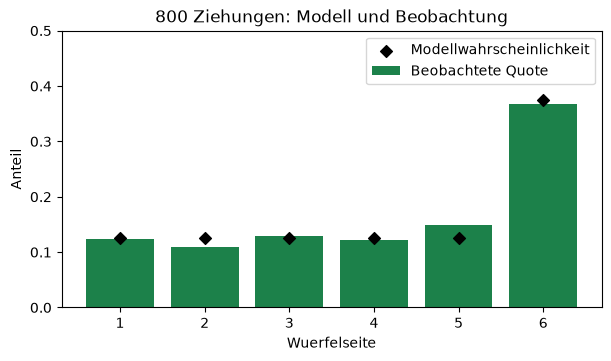

In [7]:
seiten = [1, 2, 3, 4, 5, 6]
haeufigkeiten = [gezogene_werte.count(seite) / len(gezogene_werte) for seite in seiten]
modell = [gewicht / sum(gewichte) for gewicht in gewichte]
figur, achse = plt.subplots(figsize=(6, 3.5), layout="constrained")
achse.bar(seiten, haeufigkeiten, color="#1c814a", label="Beobachtete Quote")
achse.scatter(seiten, modell, color="black", marker="D", label="Modellwahrscheinlichkeit")
achse.set(xlabel="Wuerfelseite", ylabel="Anteil", ylim=(0, 0.5), xticks=seiten,
          title="800 Ziehungen: Modell und Beobachtung")
achse.legend()
plt.show()
plt.close(figur)

## 4. Karten mit und ohne Zurücklegen
Unser einfaches Modell hat vier Typen, jeden genau einmal in der Ausgangsliste.
`choices` erlaubt denselben Typ mehrfach. `sample` wählt ohne Zurücklegen;
aus vier Einträgen können dann höchstens vier gezogen werden.
**Vorhersage:** Kann mit Zurücklegen zufällig ein Paket ohne Duplikate entstehen?
Ja. Ein einzelnes Ergebnis legt die Modellregel nicht fest.

In [8]:
typen = ["A", "B", "C", "D"]
mit_generator = Random(2026)
ohne_generator = Random(2026)
print("Mit Zuruecklegen:", mit_generator.choices(typen, k=3))
print("Ohne Zuruecklegen:", ohne_generator.sample(typen, k=3))

Mit Zuruecklegen: ['A', 'C', 'C']
Ohne Zuruecklegen: ['A', 'B', 'D']


## Eigenarbeit | 30 Minuten

**A03.1, 15 Minuten:** Verwenden Sie `faire_wuerfe` dreimal mit je zehn
Werten: Seed 2026, nochmals 2026, dann 2027. Vergleichen Sie die Listen.
Verwenden Sie danach `gewichtete_wuerfe` mit 800 Werten und Seed 2026,
einmal mit den bisherigen, einmal mit lauter gleichen Gewichten.
Notieren Sie die Modellwahrscheinlichkeit einer
Sechs und die beobachtete Quote getrennt. Wie unterscheiden sie sich vom
gezinkten Modell? Hilfe: Gewicht geteilt durch Gewichtssumme.

**A03.2, 15 Minuten:** Erzeugen Sie weitere Pakete mit drei Karten.
Benennen Sie je ein erlaubtes und ein ausgeschlossenes Ergebnis bei Ziehen
ohne Zurücklegen. Warum beweist ein Paket ohne Duplikate nicht, dass ohne
Zurücklegen gezogen wurde? Hilfe: Entscheidend ist die Funktion/Modellregel.

Ergänzen Sie eigene Zellen. Alle Demonstrationen bleiben ohne Ihre
Erweiterungen lauffähig. CR03.1 ist eine freiwillige Kategorienvertiefung,
kein zusätzliches Pflichtpensum in diesen 30 Minuten.

**Drei Dinge bleiben:** Seed dokumentieren; Gewichte normieren;
Zurücklegen und Slot-Regeln ausdrücklich nennen.
**Projekt-Brücke:** Notieren Sie Frage, Zufallsvariable und eine Annahme.
**Anschluss:** In Termin 04 liefern zwei Uniformwerte einen Punkt im Quadrat.

In [ ]:
# A03.1
# Erstellen der Funktion faire_wuerfe 
from random import Random

def faire_wuerfe(seed):
    generator = Random(seed)
    werte = []

    for i in range(10):
        wurf = generator.randint(1, 6)
        werte.append(wurf)

    return werte
# Testen der Seeds
print(faire_wuerfe(2026))
print(faire_wuerfe(2026))
print(faire_wuerfe(2027))

[1, 3, 5, 5, 6, 1, 2, 5, 5, 5]
[1, 3, 5, 5, 6, 1, 2, 5, 5, 5]
[1, 4, 1, 1, 6, 3, 4, 6, 2, 4]


In [29]:
# A03.2
from random import random
generator = Random(2027)

karten = ["Pikachu", "Glurak", "Mew", "Evoli", "Lucario", "Gengar"]

paket = generator.sample(karten, 3)

print(paket)
print(generator.sample(karten, 3))
print(generator.sample(karten, 3))

# Erlaubtes Ergebnis: ["Pikachu", "Mew", "Glurak"]
# Ausgeschlossenes Ergebnis: ["Pikachu", "Pikachu", "Mew"]

# Ein Paket ohne Duplikate beweist nicht, dass ohne Zurücklegen
# gezogen wurde, da auch beim Ziehen mit Zurücklegen zufällig
# drei unterschiedliche Karten gezogen werden können.
# Entscheidend ist die Funktion sample(), die ohne Zurücklegen zieht.

['Pikachu', 'Evoli', 'Gengar']
['Pikachu', 'Mew', 'Evoli']
['Gengar', 'Glurak', 'Evoli']



## Wahlteil | Welche Verteilung passt?
Ab hier beginnt **keine weitere Pflicht für Termin 03**. Die Beispiele
werden bei einem vollständigen technischen Lauf trotzdem ausgeführt.
Zum Lernen genügt es, eines auszuwählen und Wertebereich sowie Annahmen
zu erklären. Keine der folgenden Formeln ist für Termin 04 erforderlich.

| Modell | Beispiel und Annahme |
|---|---|
| Bernoulli | Ein Ja/Nein-Versuch mit Trefferwahrscheinlichkeit 0.3 |
| Binomial | Trefferzahl in zehn unabhängigen Versuchen mit gleichem p=0.4 |
| Poisson | Ereignisse pro Zeitfenster, konstante Rate 3 und unabhängige Zuwachse |
| Uniform | Jede gleich lange Teilstrecke von [0,1] ist gleich wahrscheinlich |
| Normal | Symmetrische Schwankung um 0; auch negative Werte sind möglich |
| Exponential | Wartezeit bei konstanter Rate 1; Gedächtnislosigkeit ist eine Annahme |
| Gamma | Summe von drei unabhängigen exponentiellen Wartezeiten mit Mittelwert 2 |
| Beta | Beispiel einer Größe zwischen 0 und 1; hier Formparameter 2 und 5 |

NumPy wird nur in diesem Wahlteil eingeführt: Ein Array ist ein Behälter
für viele Zahlen. `size=2000` erzeugt 2000 Werte; `.mean()` mittelt sie.
`.var(ddof=1)` berechnet ihre Stichprobenvarianz, also ein Streuungsmaß.
Die Vergleichswerte sind Modellmittelwerte und Modellvarianzen, keine
Forderung nach exakt gleichen Simulationsergebnissen.

In [ ]:
import numpy as np

array_generator = np.random.default_rng(2026)
beispiele = [
    ("Bernoulli", array_generator.binomial(1, 0.3, 2000), 0.3, 0.21),
    ("Binomial", array_generator.binomial(10, 0.4, 2000), 4, 2.4),
    ("Poisson", array_generator.poisson(3, 2000), 3, 3),
    ("Uniform", array_generator.uniform(0, 1, 2000), 0.5, 1 / 12),
    ("Normal", array_generator.normal(0, 1, 2000), 0, 1),
    ("Exponential", array_generator.exponential(1, 2000), 1, 1),
    ("Gamma", array_generator.gamma(3, 2, 2000), 6, 12),
    ("Beta", array_generator.beta(2, 5, 2000), 2 / 7, 10 / (49 * 8)),
]
for name, werte, modellmittel, modellvarianz in beispiele:
    print(name, "Mittel:", round(float(werte.mean()), 3), "/", round(modellmittel, 3),
          "Varianz:", round(float(werte.var(ddof=1)), 3), "/", round(modellvarianz, 3))

Bernoulli Mittel: 0.31 / 0.3 Varianz: 0.214 / 0.21
Binomial Mittel: 3.998 / 4 Varianz: 2.384 / 2.4
Poisson Mittel: 3.123 / 3 Varianz: 3.181 / 3
Uniform Mittel: 0.499 / 0.5 Varianz: 0.084 / 0.083
Normal Mittel: -0.014 / 0 Varianz: 1.012 / 1
Exponential Mittel: 0.993 / 1 Varianz: 1.005 / 1
Gamma Mittel: 6.012 / 6 Varianz: 11.871 / 12
Beta Mittel: 0.291 / 0.286 Varianz: 0.025 / 0.026


## Wahlteil | Eine positive Wartezeit aus einem Uniformwert
Ein Generator kann Uniformwerte transformieren. Für eine exponentielle
Wartezeit mit Rate 2 pro Minute lautet die Regel `-log(1-u) / 2`.
Der Modellmittelwert ist dann 1/2 Minute. `log` ist der natürliche Logarithmus.
`log1p(-u)` berechnet `log(1-u)` numerisch stabil, auch bei sehr kleinen u.
Die Uniformwerte liegen unter 1, deshalb ist der Logarithmus definiert.

Dieses Beispiel erhält die Transformationsmethode aus der alten Übung,
ist aber keine Pflichtimplementierung vor der ersten Monte-Carlo-Einheit.

In [ ]:
warte_generator = Random(2026)
wartezeiten = []
for versuch in range(2000):
    uniformwert = warte_generator.random()
    wartezeiten.append(-math.log1p(-uniformwert) / 2)
print("Mittlere Wartezeit in Minuten:", sum(wartezeiten) / len(wartezeiten))
print("Modellmittelwert in Minuten:", 0.5)

Mittlere Wartezeit in Minuten: 0.4966130464607509
Modellmittelwert in Minuten: 0.5


## Wahlteil | Modellgrenzen bei Karten
Das Grundmodell unabhängiger Ziehungen kann Seltenheiten C/U/R mit
Wahrscheinlichkeiten 0.78/0.20/0.02 verwenden. Ein garantierter U- oder R-Slot
ist dagegen eine zusätzliche Regel: Ein solcher Slot wird nur aus U/R gezogen,
beispielsweise mit relativen Gewichten 0.20/0.02. Seine Verteilung ist nicht
mehr die unveränderte Grundverteilung. Ebenso verändern feste Slotanzahlen
wie acht C, eine U und eine R die Verteilung eines gesamten Pakets.

PRNG ist algorithmischer Pseudozufall, TRNG stammt aus einem physikalischen
Prozess. Ein gleichmäßiges Histogramm allein prüft keine Unabhängigkeit.
Große Sammelstudien und Sensitivität folgen erst nach Unsicherheit und
Experimentplanung; ihr Status steht in der Quellenzuordnung.